# Exploratory data analysis of fluorescent microscopy images

In [12]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tifffile

DATA_DIR = Path("data")
METADATA_DIR = DATA_DIR / "metadata"
RAW_DIR = DATA_DIR / "raw"

pairs = pd.read_csv(METADATA_DIR / "valid_pairs.csv")

print(f"Total pairs: {len(pairs):,}")
print(f"Studies: {pairs['study'].nunique()}")
print(f"Modalities: {pairs['modality'].unique()}")

Total pairs: 2,532
Studies: 29
Modalities: <StringArray>
['BF', 'DIC', 'PC']
Length: 3, dtype: str


## Number of paired images per study

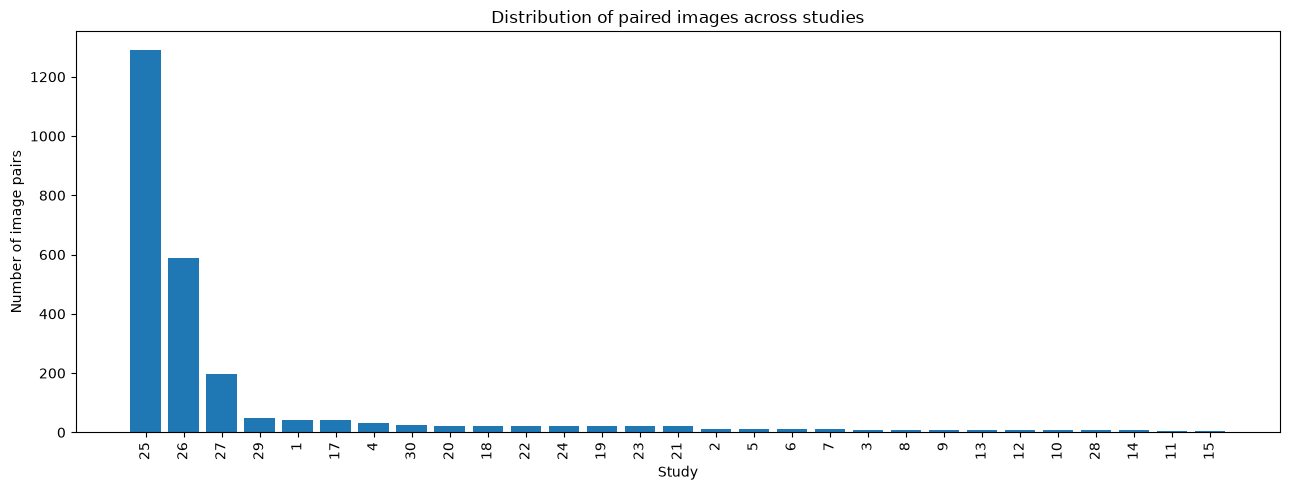

In [13]:
study_counts = pairs.groupby("study").size().sort_values(ascending=False)

plt.figure(figsize=(13, 5))

plt.bar(study_counts.index.astype(str), study_counts.values)

plt.xlabel("Study")
plt.ylabel("Number of image pairs")
plt.title("Distribution of paired images across studies")

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

## Distribution of microscopy modalities

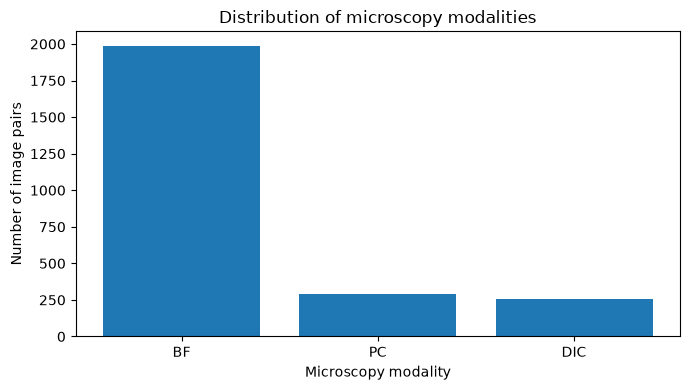

In [14]:
modality_counts = pairs["modality"].value_counts()

plt.figure(figsize=(7, 4))

plt.bar(modality_counts.index, modality_counts.values)

plt.xlabel("Microscopy modality")
plt.ylabel("Number of image pairs")
plt.title("Distribution of microscopy modalities")

plt.tight_layout()
plt.show()

## Study × modality heatmap

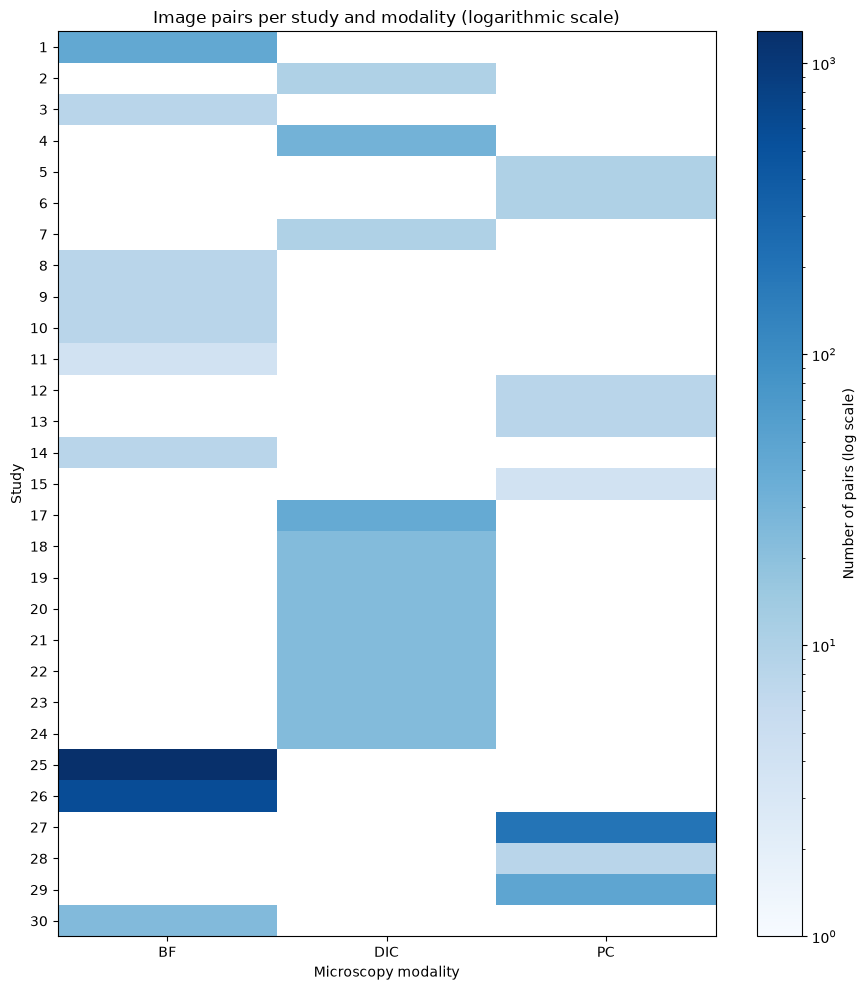

In [15]:
from matplotlib.colors import LogNorm

study_modality = pd.crosstab(
    pairs["study"],
    pairs["modality"]
)

fig, ax = plt.subplots(figsize=(9, 10))

values = study_modality.values

im = ax.imshow(
    np.ma.masked_equal(values, 0),
    cmap="Blues",
    norm=LogNorm(vmin=1, vmax=values.max()),
    aspect="auto"
)

ax.set_xticks(range(len(study_modality.columns)))
ax.set_xticklabels(study_modality.columns)

ax.set_yticks(range(len(study_modality.index)))
ax.set_yticklabels(study_modality.index)

ax.set_xlabel("Microscopy modality")
ax.set_ylabel("Study")
ax.set_title("Image pairs per study and modality (logarithmic scale)")

fig.colorbar(im, ax=ax, label="Number of pairs (log scale)")

plt.tight_layout()
plt.show()

## Raw image and fluorescence image sample

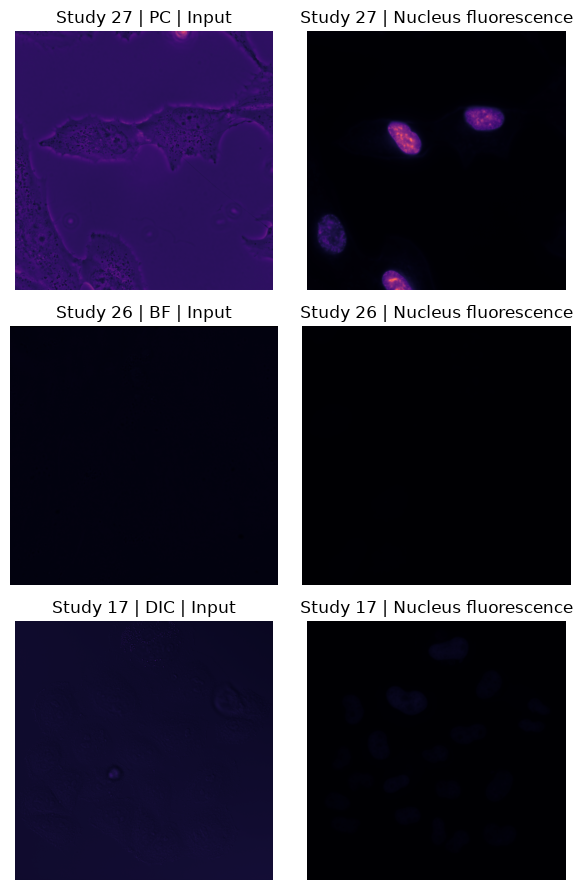

In [ ]:
n_samples = 3

sample = pairs.sample(n=n_samples, random_state=42)

fig, axes = plt.subplots(n_samples, 2, figsize=(6, 3 * n_samples))

for i, row in enumerate(sample.itertuples(index=False)):
    folder = RAW_DIR / f"Study_{row.study}"

    x = tifffile.imread(folder / row.input_file)
    y = tifffile.imread(folder / row.target_file)

    axes[i, 0].imshow(x, cmap="gray", vmin=0, vmax=65535)
    axes[i, 1].imshow(y, cmap="gray", vmin=0, vmax=65535)

    axes[i, 0].set_title(
        f"Study {row.study} | {row.modality} | Input"
    )
    axes[i, 1].set_title(
        f"Study {row.study} | Nucleus fluorescence"
    )

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

## Compare raw and normalized images

Since the raw images will be normalized to the range [0, 1], we can visualize the difference between the raw and normalized images. This can help us understand how the normalization process affects the image data.

### Calculate the percentile normalization for each image

In [19]:
import numpy as np

def percentile_normalize(image, low=1, high=99):
    p_low, p_high = np.percentile(image, [low, high])

    if p_high <= p_low:
        return np.zeros_like(image, dtype=np.float32)

    normalized = (
        image.astype(np.float32) - p_low
    ) / (p_high - p_low)

    return np.clip(normalized, 0, 1)

### Display the raw and normalized images side by side

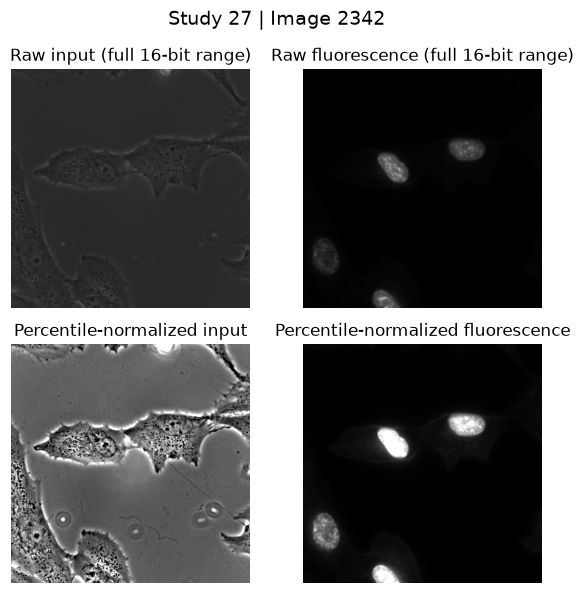

In [22]:
row = pairs.sample(n=1, random_state=42).iloc[0]

folder = RAW_DIR / f"Study_{row['study']}"

x = tifffile.imread(folder / row["input_file"])
y = tifffile.imread(folder / row["target_file"])

fig, axes = plt.subplots(2, 2, figsize=(6, 6))

axes[0, 0].imshow(x, cmap="gray", vmin=0, vmax=65535)
axes[0, 0].set_title("Raw input (full 16-bit range)")

axes[0, 1].imshow(y, cmap="gray", vmin=0, vmax=65535)
axes[0, 1].set_title("Raw fluorescence (full 16-bit range)")

axes[1, 0].imshow(percentile_normalize(x), cmap="gray", vmin=0, vmax=1)
axes[1, 0].set_title("Percentile-normalized input")

axes[1, 1].imshow(percentile_normalize(y), cmap="gray", vmin=0, vmax=1)
axes[1, 1].set_title("Percentile-normalized fluorescence")

for ax in axes.flat:
  ax.axis("off")

fig.suptitle(f"Study {row['study']} | Image {row['image_id']}", fontsize=14)
fig.tight_layout()
plt.show()


## One pair from every study

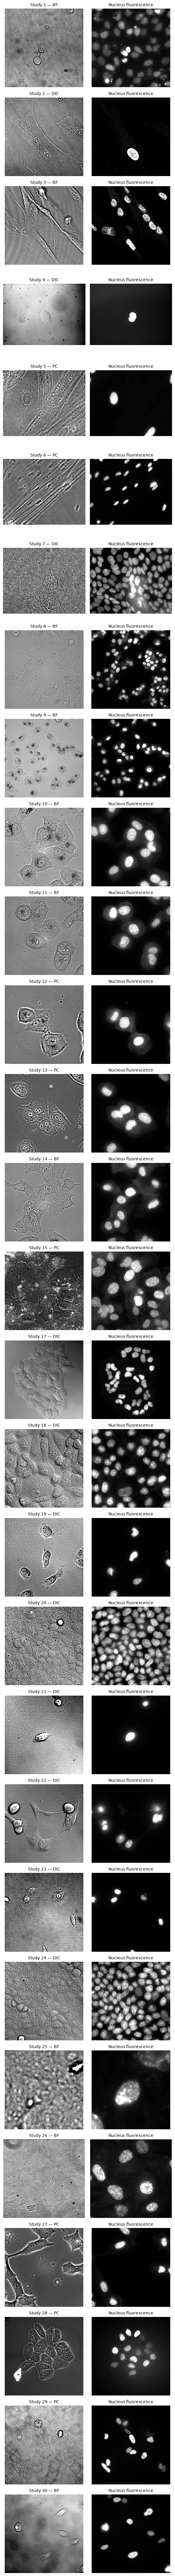

In [24]:
study_samples = (
    pairs.groupby("study", group_keys=False)
    .sample(n=1, random_state=42)
    .sort_values("study")
)

fig, axes = plt.subplots(
    len(study_samples), 2,
    figsize=(6, len(study_samples) * 3)
)

for i, row in enumerate(study_samples.itertuples(index=False)):
    folder = RAW_DIR / f"Study_{row.study}"

    x = tifffile.imread(folder / row.input_file)
    y = tifffile.imread(folder / row.target_file)

    for ax, image, title in zip(
        axes[i],
        [x, y],
        [
            f"Study {row.study} — {row.modality}",
            "Nucleus fluorescence"
        ]
    ):
        ax.imshow(
            image,
            cmap="gray",
            vmin=np.percentile(image, 1),
            vmax=np.percentile(image, 99)
        )
        ax.set_title(title, fontsize=10)
        ax.axis("off")

plt.tight_layout()
plt.show()

## Dataset summary statistics

In [25]:
STATS_PATH = METADATA_DIR / "image_statistics.csv"

def image_stats(image):
    pixels = image[::8, ::8].astype(np.float32)

    p1, p25, p50, p75, p99 = np.percentile(
        pixels, [1, 25, 50, 75, 99]
    )

    return {
        "mean": pixels.mean(),
        "std": pixels.std(),
        "min": pixels.min(),
        "max": pixels.max(),
        "p1": p1,
        "p25": p25,
        "p50": p50,
        "p75": p75,
        "p99": p99
    }

if STATS_PATH.exists():
    stats_df = pd.read_csv(STATS_PATH)
else:
    records = []

    for i, row in enumerate(pairs.itertuples(index=False), 1):
        folder = RAW_DIR / f"Study_{row.study}"

        for channel, filename in [
            ("input", row.input_file),
            ("target", row.target_file)
        ]:
            image = tifffile.imread(folder / filename)

            records.append({
                "study": row.study,
                "image_id": row.image_id,
                "modality": row.modality,
                "channel": channel,
                **image_stats(image)
            })

        if i % 100 == 0:
            print(f"Analyzed {i}/{len(pairs)} pairs")

    stats_df = pd.DataFrame(records)
    stats_df.to_csv(STATS_PATH, index=False)

display(stats_df.head())

Analyzed 100/2532 pairs
Analyzed 200/2532 pairs
Analyzed 300/2532 pairs
Analyzed 400/2532 pairs
Analyzed 500/2532 pairs
Analyzed 600/2532 pairs
Analyzed 700/2532 pairs
Analyzed 800/2532 pairs
Analyzed 900/2532 pairs
Analyzed 1000/2532 pairs
Analyzed 1100/2532 pairs
Analyzed 1200/2532 pairs
Analyzed 1300/2532 pairs
Analyzed 1400/2532 pairs
Analyzed 1500/2532 pairs
Analyzed 1600/2532 pairs
Analyzed 1700/2532 pairs
Analyzed 1800/2532 pairs
Analyzed 1900/2532 pairs
Analyzed 2000/2532 pairs
Analyzed 2100/2532 pairs
Analyzed 2200/2532 pairs
Analyzed 2300/2532 pairs
Analyzed 2400/2532 pairs
Analyzed 2500/2532 pairs


,study,image_id,modality,channel,mean,std,min,max,p1,p25,p50,p75,p99
0,1,0,BF,input,1040.763550,93.440201,427.0,2761.0,812.35,990.0,1040.0,1089.0,1307.0
1,1,0,BF,target,209.600449,71.458855,112.0,1539.0,152.00,176.0,192.0,225.0,404.0
2,1,1,BF,input,1298.899536,90.764633,551.0,3278.0,1058.00,1250.0,1299.0,1349.0,1507.0
3,1,1,BF,target,194.123413,88.685707,86.0,2606.0,135.00,157.0,171.0,212.0,442.0
4,1,2,BF,input,941.712585,119.025963,364.0,3216.0,677.00,871.0,934.0,1003.0,1287.0


## Plot intensity across studies

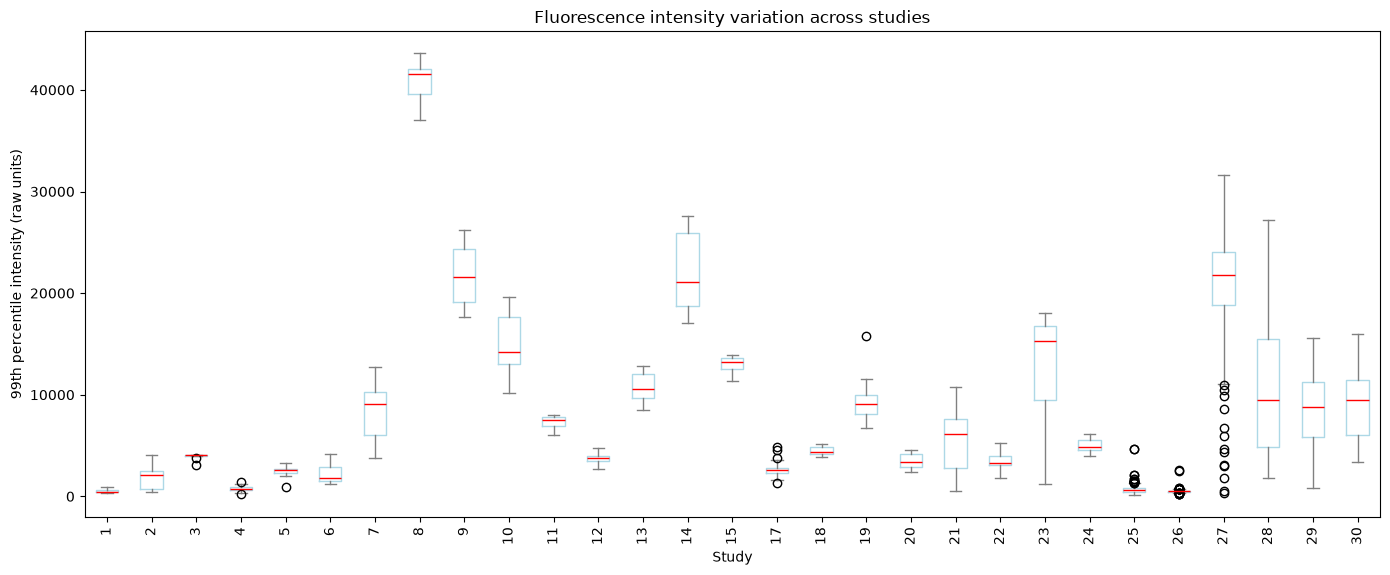

In [ ]:
target_stats = stats_df[stats_df["channel"] == "target"]

fig, ax = plt.subplots(figsize=(14, 6))

target_stats.boxplot(
    column="p99",
    by="study",
    color=dict(boxes='lightblue', whiskers='gray', medians='red', caps='gray'),
    ax=ax,
    rot=90,
    grid=False
)

ax.set_title("Fluorescence intensity variation across studies")
ax.set_xlabel("Study")
ax.set_ylabel("99th percentile intensity (raw units)")

plt.suptitle("")
plt.tight_layout()
plt.show()

## Compare input image contrast

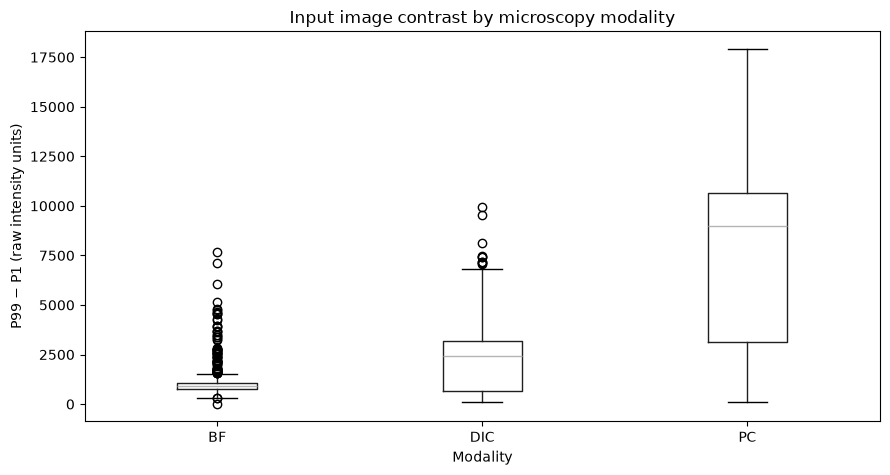

In [27]:
input_stats = stats_df[stats_df["channel"] == "input"].copy()

input_stats["contrast_range"] = (
    input_stats["p99"] - input_stats["p1"]
)

fig, ax = plt.subplots(figsize=(9, 5))

input_stats.boxplot(
    column="contrast_range",
    by="modality",
    ax=ax,
    grid=False
)

ax.set_title("Input image contrast by microscopy modality")
ax.set_xlabel("Modality")
ax.set_ylabel("P99 − P1 (raw intensity units)")

plt.suptitle("")
plt.tight_layout()
plt.show()

## Fluorescence dynamic range

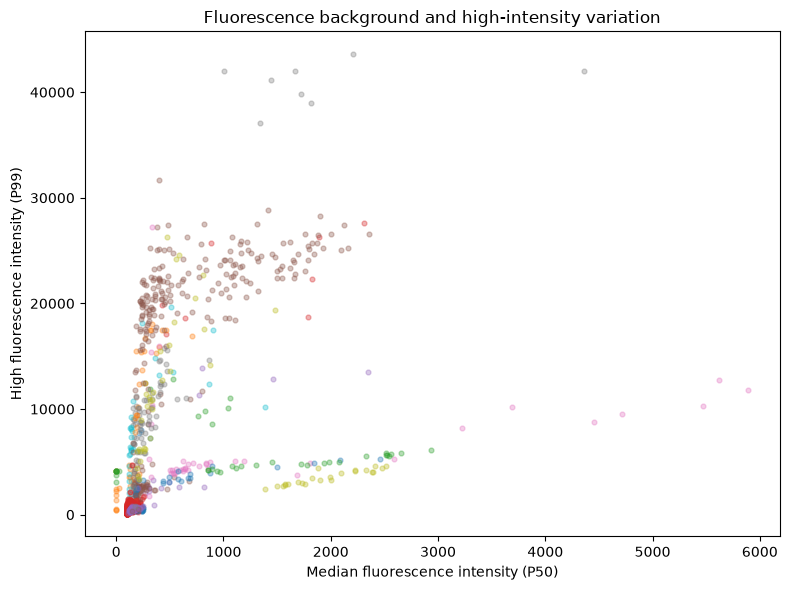

In [28]:
fig, ax = plt.subplots(figsize=(8, 6))

for study, group in target_stats.groupby("study"):
    ax.scatter(
        group["p50"],
        group["p99"],
        alpha=0.35,
        s=12
    )

ax.set_xlabel("Median fluorescence intensity (P50)")
ax.set_ylabel("High fluorescence intensity (P99)")
ax.set_title("Fluorescence background and high-intensity variation")

plt.tight_layout()
plt.show()

## Input–target overlays across modalities

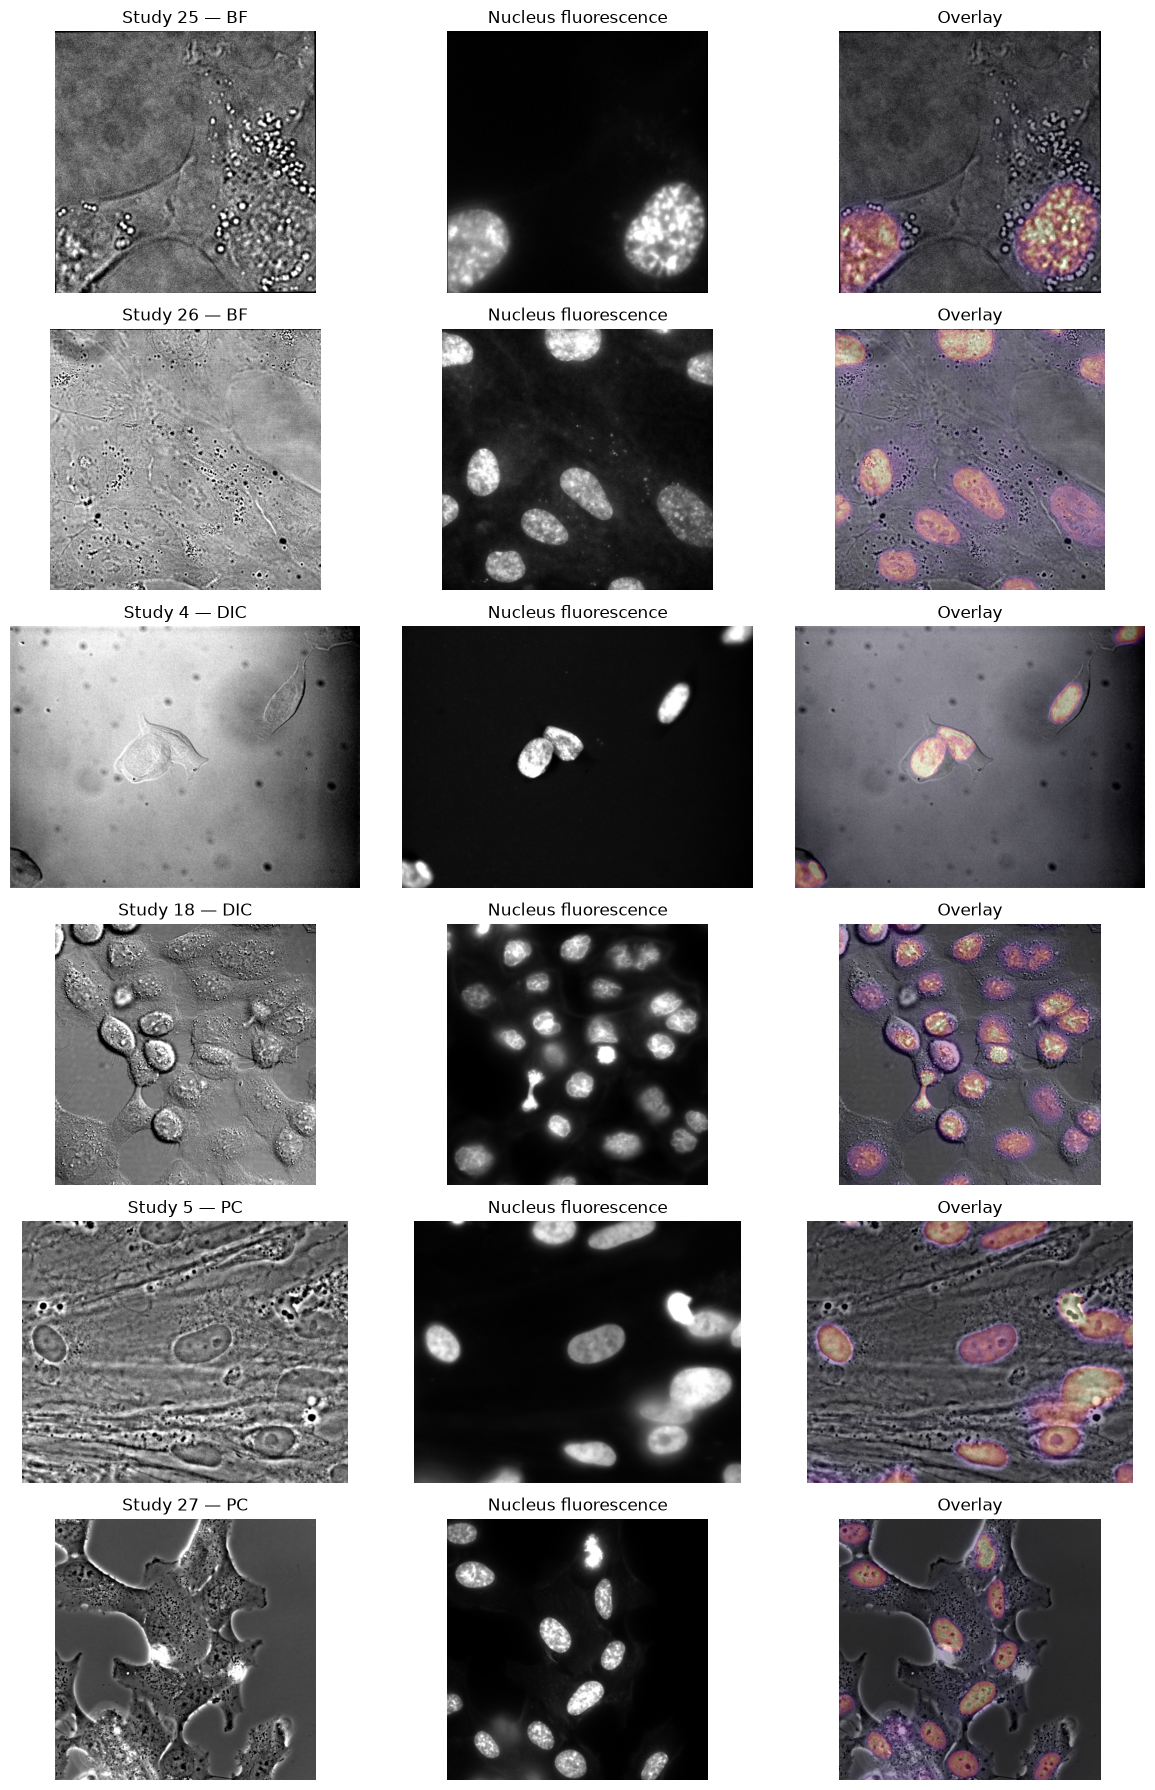

In [ ]:
def display_normalize(image):
    low, high = np.percentile(image, [1, 99])
    return np.clip(
        (image.astype(np.float32) - low) / max(high - low, 1),
        0, 1
    )

samples = (
    pairs.groupby("modality", group_keys=False)
    .sample(n=2, random_state=42)
    .sort_values("modality")
)

fig, axes = plt.subplots(len(samples), 3, figsize=(12, 3 * len(samples)))

for i, row in enumerate(samples.itertuples(index=False)):
    folder = RAW_DIR / f"Study_{row.study}"

    x = tifffile.imread(folder / row.input_file)
    y = tifffile.imread(folder / row.target_file)

    x_display = display_normalize(x)
    y_display = display_normalize(y)

    axes[i, 0].imshow(x_display, cmap="gray")
    axes[i, 1].imshow(y_display, cmap="gray")

    axes[i, 2].imshow(x_display, cmap="gray")
    axes[i, 2].imshow(y_display, cmap="magma", alpha=0.4)

    for ax in axes[i]:
        ax.axis("off")

    axes[i, 0].set_title(f"Study {row.study} — {row.modality}")
    axes[i, 1].set_title("Nucleus fluorescence")
    axes[i, 2].set_title("Overlay")

plt.tight_layout()
plt.show()